# 02 · The maths under ML: gradient descent, optimisers, loss functions, vectors

**Time:** ~2 hours. Every section has a small picture; understand the picture, then the formula.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
rng = np.random.default_rng(0)

## 1. Learning rate: too small, good, too big
Minimise f(w) = w² (gradient 2w). Update: w ← w − lr · gradient.

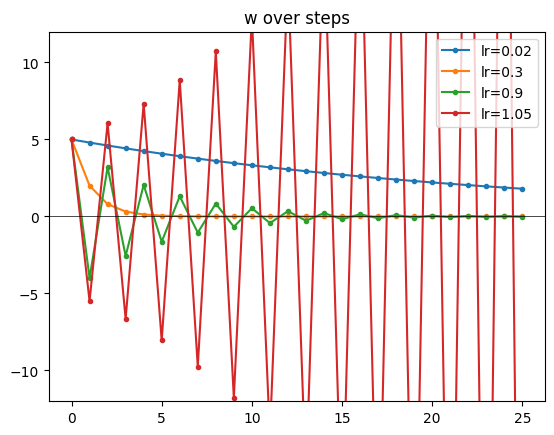

In [2]:
def run(lr, w0=5.0, steps=25):
    w, path = w0, [w0]
    for _ in range(steps):
        w = w - lr * 2 * w; path.append(w)
    return np.array(path)
for lr in [0.02, 0.3, 0.9, 1.05]:
    plt.plot(run(lr), "o-", ms=3, label=f"lr={lr}")
plt.ylim(-12, 12); plt.axhline(0, c="k", lw=0.5); plt.legend(); plt.title("w over steps"); plt.show()

lr > 1 diverges here (for w², the limit is 2 / curvature = 1). In deep learning: loss → NaN means the
learning rate is too high (or bad data).

## 2. Batch vs stochastic vs mini-batch gradient descent

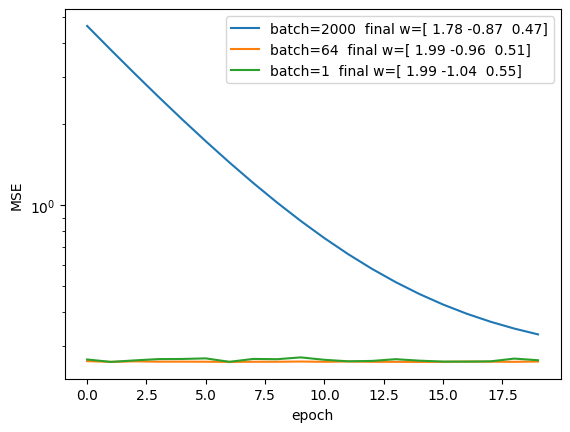

In [3]:
n = 2000
X = rng.normal(size=(n, 3)); w_true = np.array([2.0, -1.0, 0.5]); y = X @ w_true + rng.normal(0, 0.5, n)

def train(batch, lr=0.05, epochs=20):
    w, losses = np.zeros(3), []
    for _ in range(epochs):
        idx = rng.permutation(n)
        for s in range(0, n, batch):
            b = idx[s:s + batch]
            w -= lr * 2 * X[b].T @ (X[b] @ w - y[b]) / len(b)
        losses.append(((X @ w - y) ** 2).mean())
    return w, losses
for batch in [n, 64, 1]:
    w, l = train(batch, lr=0.05 if batch > 1 else 0.005)
    plt.plot(l, label=f"batch={batch}  final w={w.round(2)}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

Mini-batches give a good trade-off: cheaper steps than full batch, less noise than single samples, and
they use the GPU well.

## 3. Optimisers on a hard surface: SGD vs momentum vs Adam
The Rosenbrock "banana" function has a long curved valley.

SGD           final point [0.198 0.036]  loss 0.6443


SGD+momentum  final point [0.999 0.998]  loss 0.0000


Adam          final point [0.96  0.921]  loss 0.0016


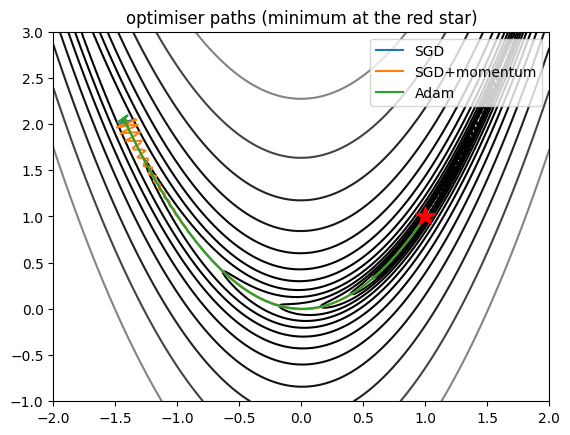

In [4]:
def rosen(p):
    x, y = p[0], p[1]
    return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2

paths = {}
for name, make in {"SGD": lambda q: torch.optim.SGD([q], lr=1e-3),
                   "SGD+momentum": lambda q: torch.optim.SGD([q], lr=1e-3, momentum=0.9),
                   "Adam": lambda q: torch.optim.Adam([q], lr=2e-2)}.items():
    p = torch.tensor([-1.5, 2.0], requires_grad=True); opt = make(p); path = []
    for _ in range(1500):
        opt.zero_grad(); loss = rosen(p); loss.backward(); opt.step(); path.append(p.detach().numpy().copy())
    paths[name] = np.array(path)
    print(f"{name:13} final point {path[-1].round(3)}  loss {rosen(torch.tensor(path[-1])).item():.4f}")

xs, ys = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-1, 3, 200))
plt.contour(xs, ys, (1 - xs) ** 2 + 100 * (ys - xs ** 2) ** 2, levels=np.logspace(-1, 3, 15), cmap="gray")
for name, pth in paths.items():
    plt.plot(pth[:, 0], pth[:, 1], label=name)
plt.plot(1, 1, "r*", ms=15); plt.legend(); plt.title("optimiser paths (minimum at the red star)"); plt.show()

- **Momentum** keeps a running average of gradients → speeds through flat valleys.
- **Adam** = momentum + per-parameter step sizes (divides by running RMS of gradients). Default for deep learning.

## 4. Loss functions side by side

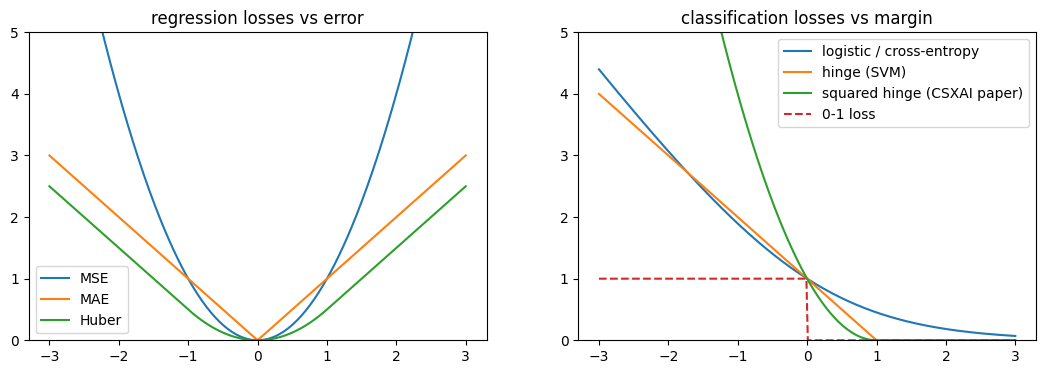

In [5]:
e = np.linspace(-3, 3, 300)
huber = np.where(np.abs(e) <= 1, 0.5 * e ** 2, np.abs(e) - 0.5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(e, e ** 2, label="MSE"); axes[0].plot(e, np.abs(e), label="MAE"); axes[0].plot(e, huber, label="Huber")
axes[0].set_title("regression losses vs error"); axes[0].legend(); axes[0].set_ylim(0, 5)

m = np.linspace(-3, 3, 300)                     # margin = y·f(x), y in {-1,+1}
axes[1].plot(m, np.log2(1 + np.exp(-m)), label="logistic / cross-entropy")
axes[1].plot(m, np.maximum(0, 1 - m), label="hinge (SVM)")
axes[1].plot(m, np.maximum(0, 1 - m) ** 2, label="squared hinge (CSXAI paper)")
axes[1].plot(m, (m < 0).astype(float), label="0-1 loss", ls="--")
axes[1].set_title("classification losses vs margin"); axes[1].legend(); axes[1].set_ylim(0, 5)
plt.show()

MSE punishes outliers most; MAE is robust; Huber is in between. Hinge loss is zero once a point is
correctly classified with margin ≥ 1, so the model focuses on hard points near the boundary.

## 5. Softmax and numerically stable cross-entropy

In [6]:
def softmax(z):
    z = z - z.max(axis=-1, keepdims=True)        # subtract max: same result, no overflow
    ez = np.exp(z); return ez / ez.sum(axis=-1, keepdims=True)
logits = np.array([1000.0, 1001.0, 1002.0])
print("naive:", np.exp(logits) / np.exp(logits).sum())   # overflow -> nan
print("stable:", softmax(logits).round(4))
p = softmax(np.array([2.0, 0.5, -1.0])); print("cross-entropy if true class = 0:", round(-np.log(p[0]), 4))

naive: [nan nan nan]
stable: [0.09   0.2447 0.6652]
cross-entropy if true class = 0: 0.2413


## 6. Vectors: dot product, cosine similarity, matrix shapes
Embedding search ranks documents by cosine similarity = (a·b) / (‖a‖‖b‖). If vectors are normalised,
cosine = dot product, which is why vector databases normalise.

In [7]:
a, b = rng.normal(size=384), rng.normal(size=384)
cos = a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
an, bn = a / np.linalg.norm(a), b / np.linalg.norm(b)
print("cosine:", round(cos, 4), "| dot of normalised:", round(an @ bn, 4))

# a dense layer: (batch, in) @ (in, out) + (out,) -> (batch, out)
x = rng.normal(size=(32, 768)); W = rng.normal(size=(768, 3072)); bias = np.zeros(3072)
print("dense output shape:", (x @ W + bias).shape, "| parameters:", W.size + bias.size)

cosine: 0.0532 | dot of normalised: 0.0532
dense output shape: (32, 3072) | parameters: 2362368


## ✍️ Your turn
1. Implement Adam yourself in NumPy for the Rosenbrock function and match PyTorch's path.
2. Show that MSE regression is pulled by one large outlier while MAE is not (fit both on data with one outlier).
3. Count the parameters of a transformer block with d_model = 4096 (attention 4·d² + MLP 8·d²).

## 🎯 Interview check
- Why does Adam often train faster than SGD? When might SGD generalise better?
- Why subtract the max inside softmax?
- Cosine similarity vs Euclidean distance for embeddings?
- What happens to gradients with a very deep network and sigmoid activations?

In [8]:
# Your code here